CONFIGURAÇÕES DE POLOS E ZEROS
Configuração                                      K   max|H|  min|H| (dB)  ω do máx/π  erro vetores x freqz_zpk
----------------------------------------------------------------------------------------------------------------
A. Polo real positivo (0,8)                  0.2000   1.0000       -19.08       0.000                  4.45e-16
B. Polo real negativo (-0,8)                 0.2000   1.0000       -19.08       1.000                  2.38e-15
C. Zero em z = 1, polo em 0,9                0.9500   1.0000  -inf (nulo)       1.000                  5.56e-16
D. Zero em z = -1, polo em 0,5               0.2500   1.0000  -inf (nulo)       0.000                  4.58e-16
E. Polos 0,9e^{±jπ/3}                        0.1645   1.0000       -24.33       0.332                  1.74e-15
F. Zeros e^{±jπ/2}, polos 0,9e^{±jπ/2}       0.9050   1.0000  -inf (nulo)       1.000                  2.12e-15
G. Zeros em ±1, polos 0,9e^{±jπ/2}           0.0950   1.0000  -inf (nulo

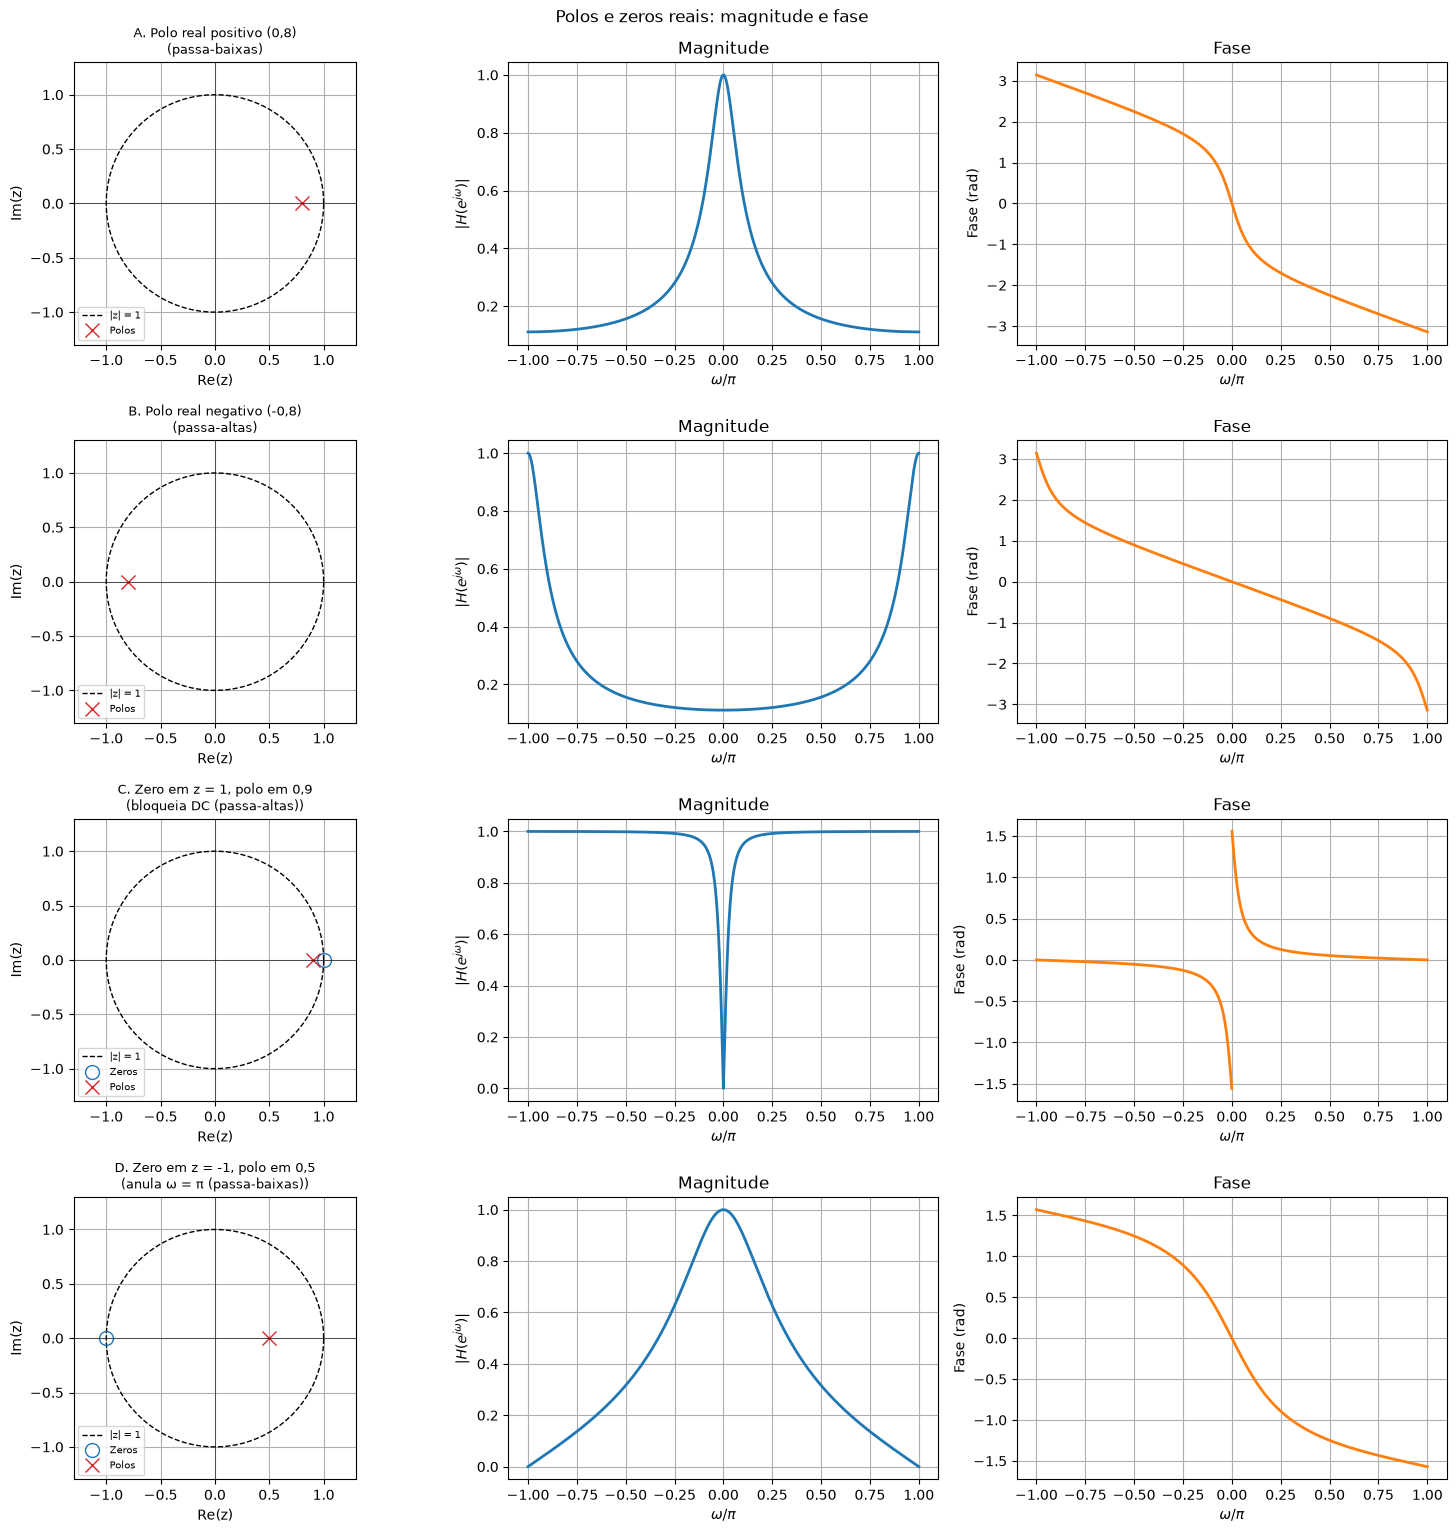

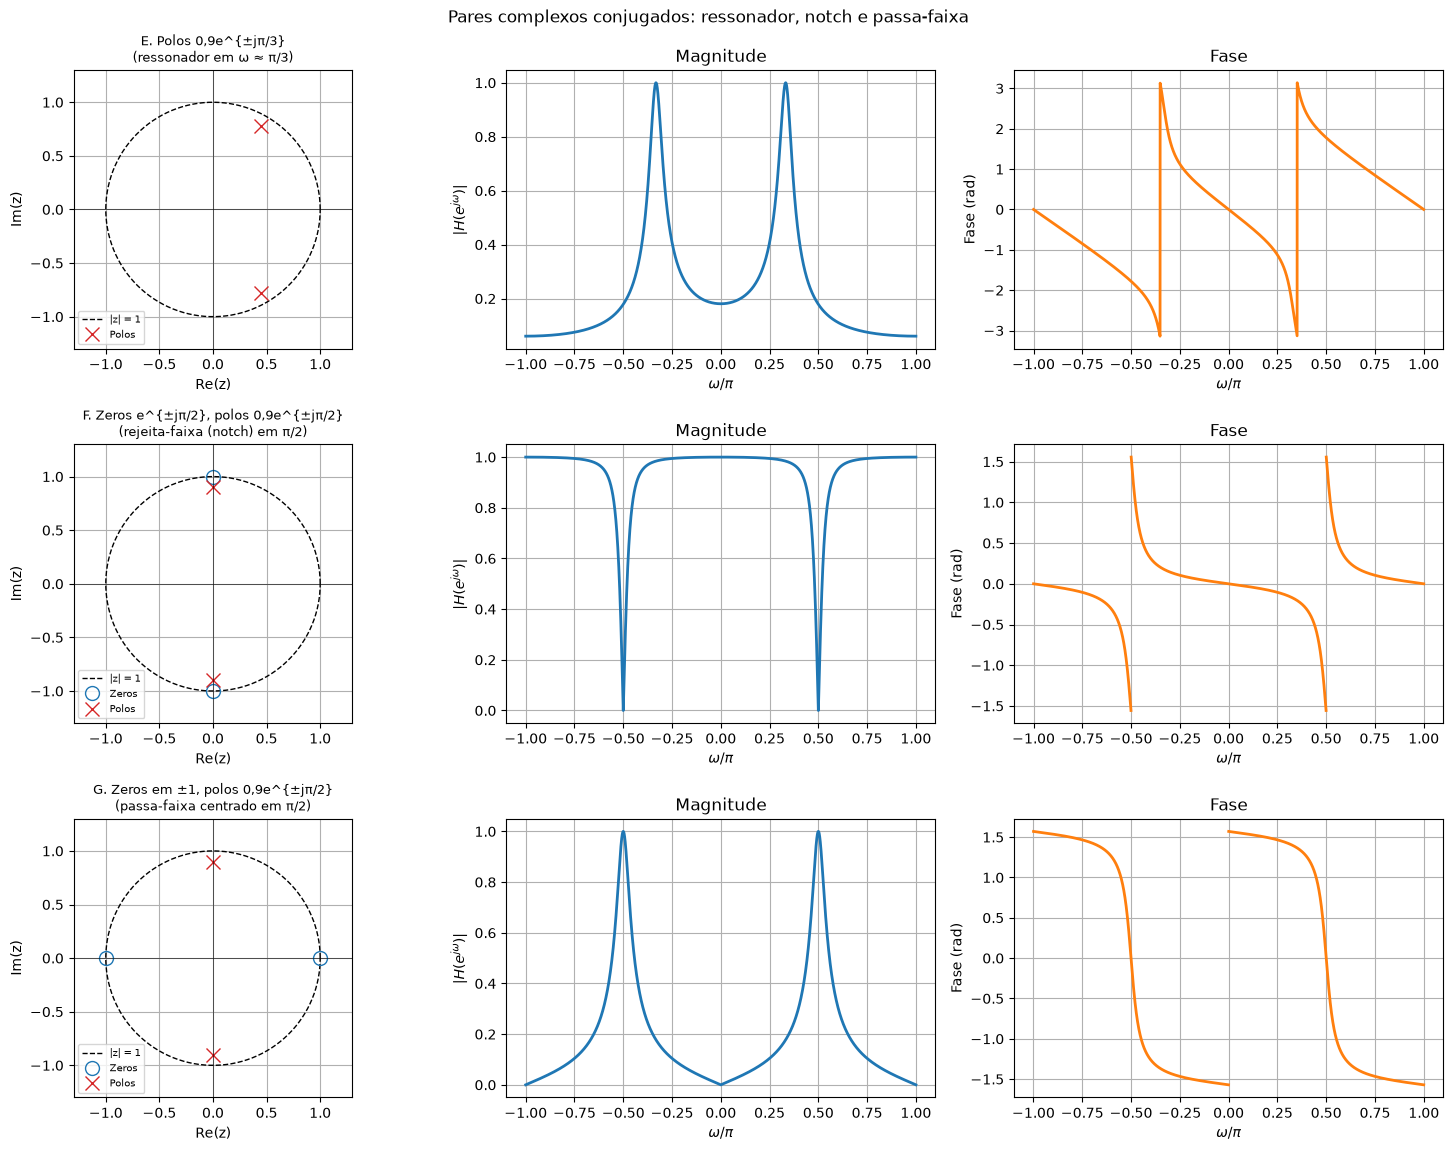

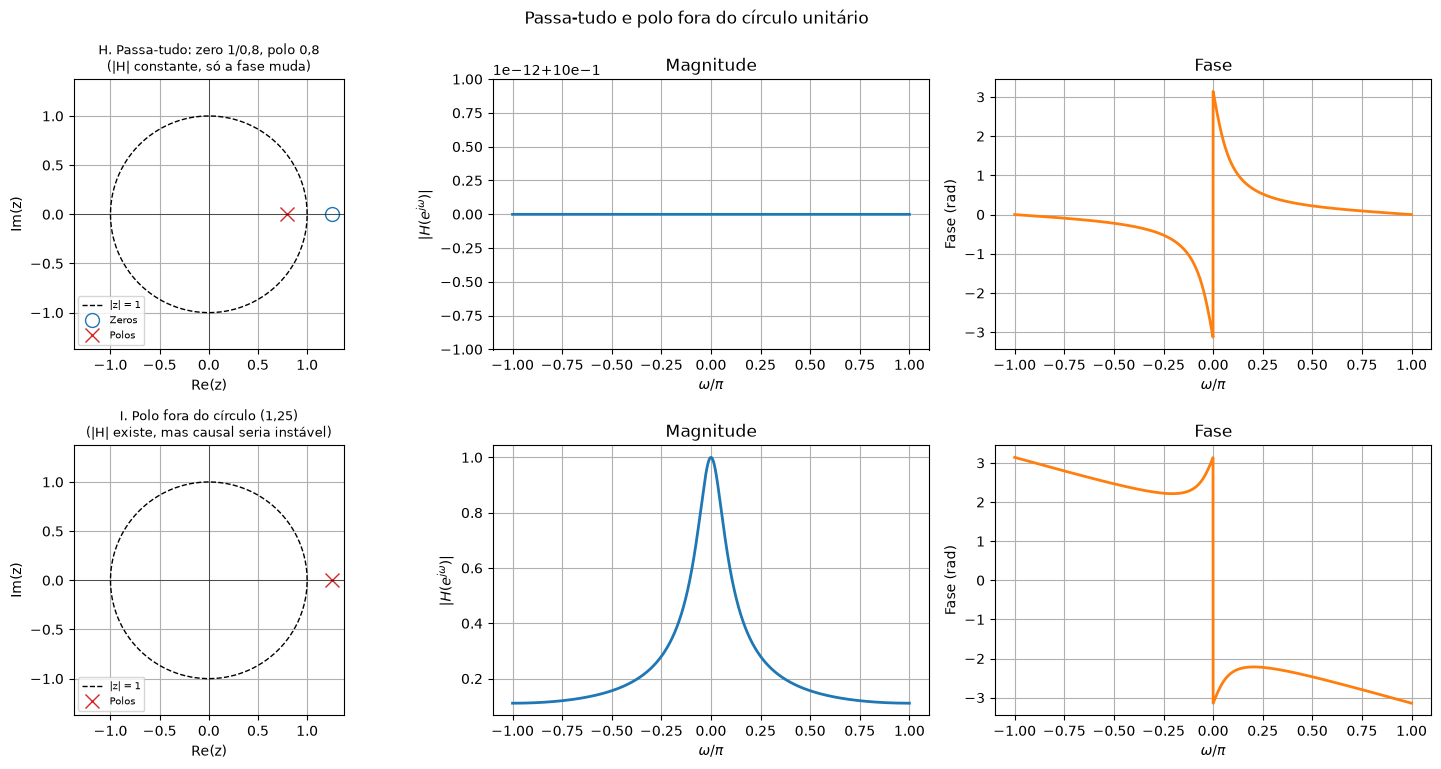

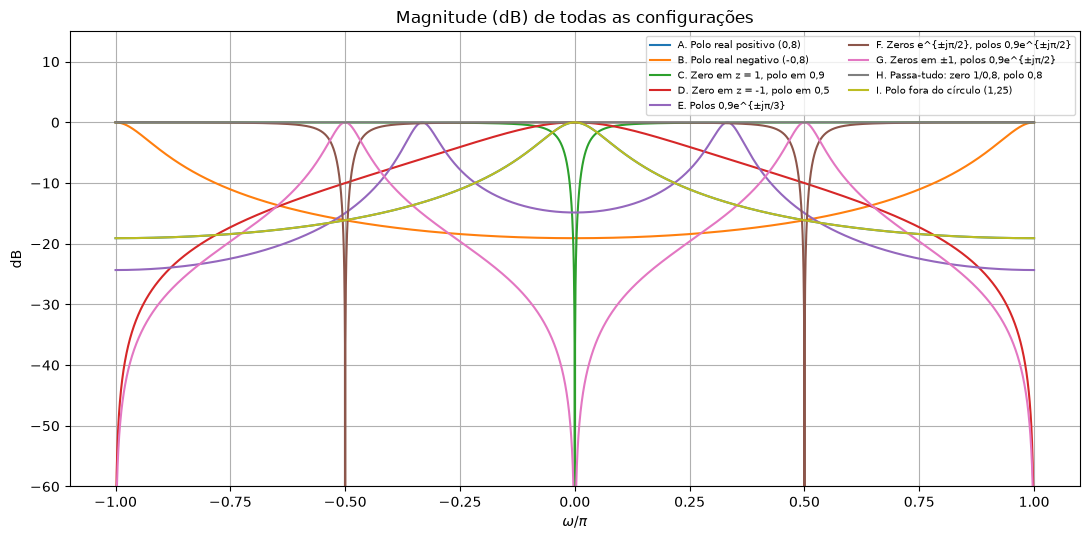

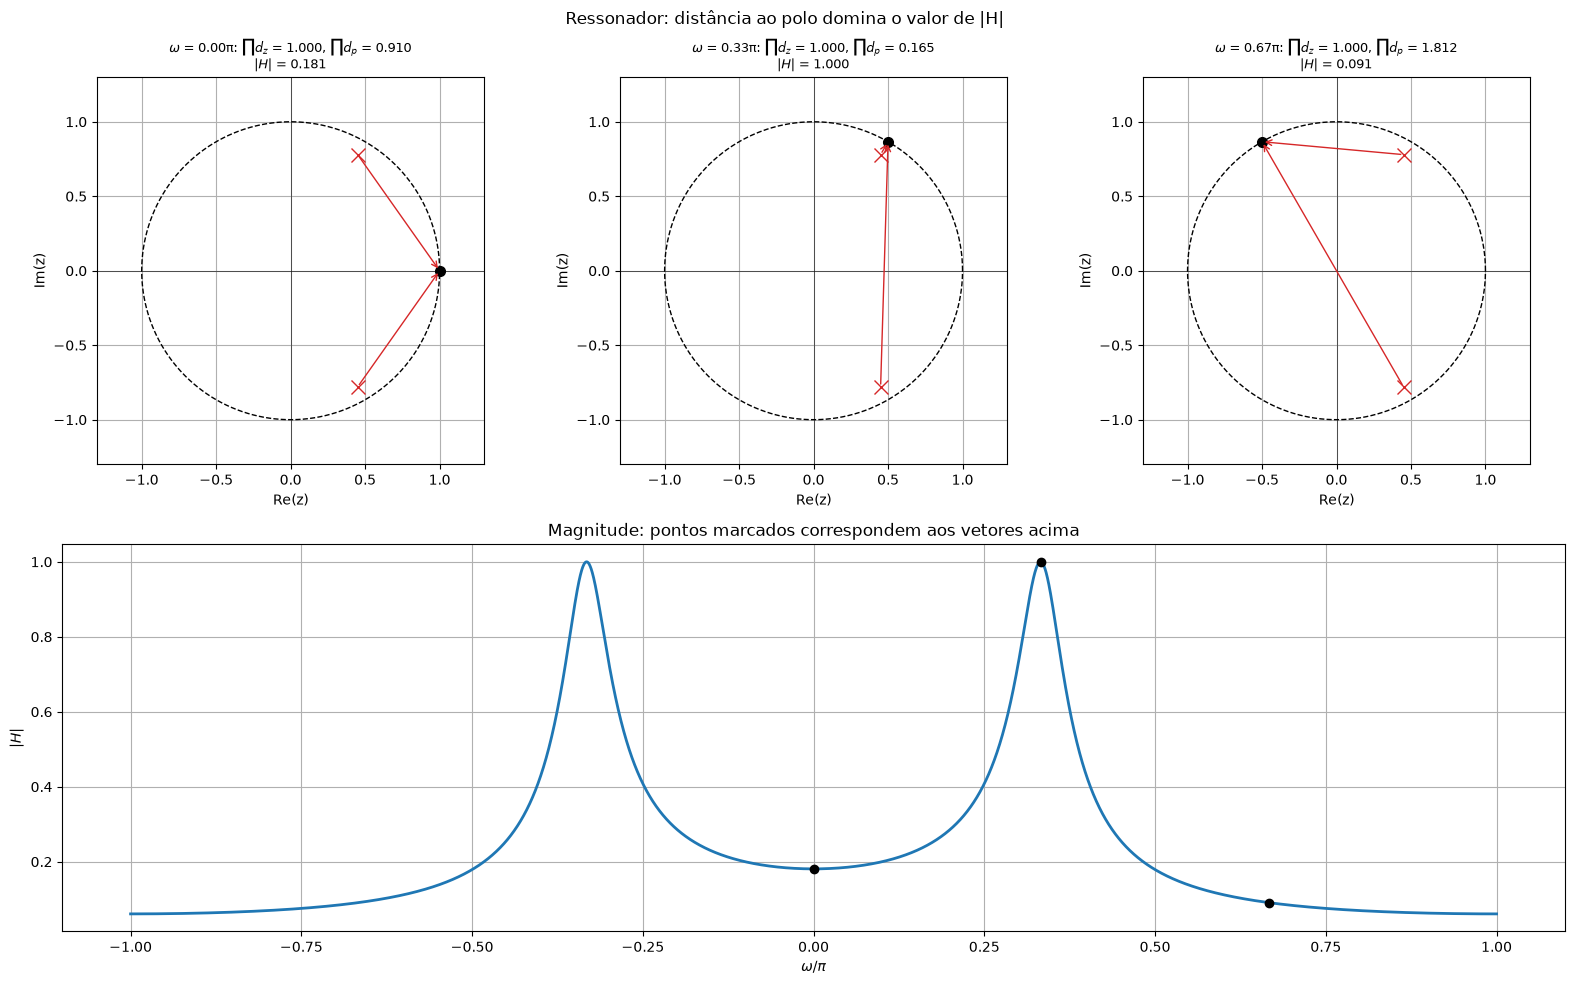

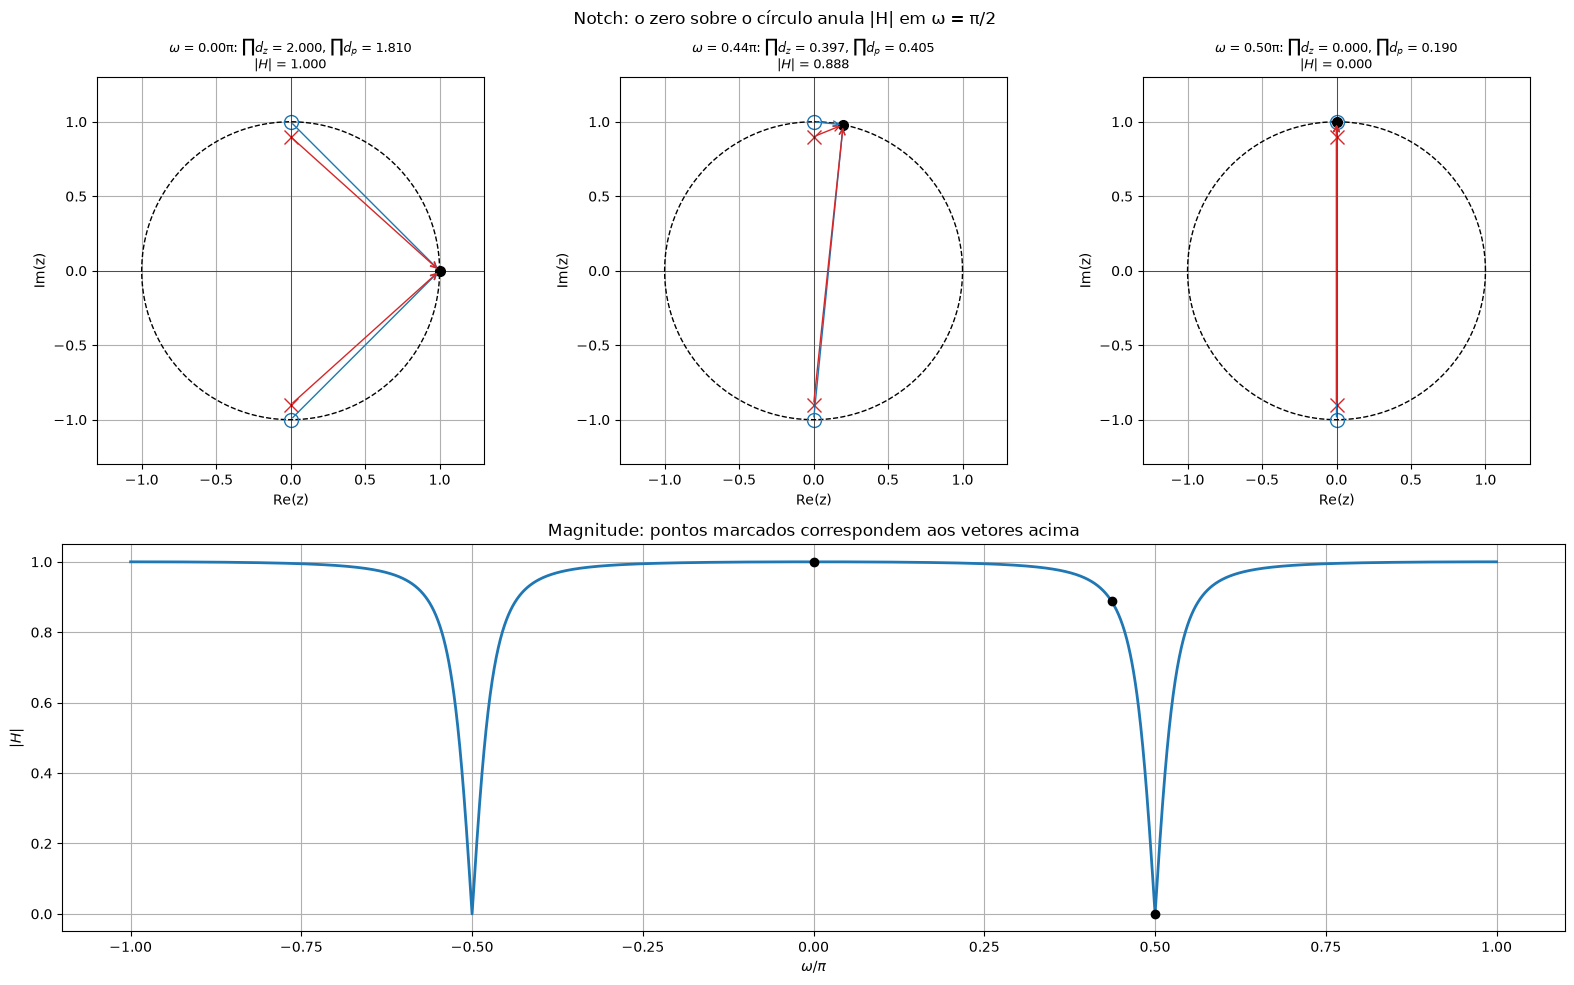

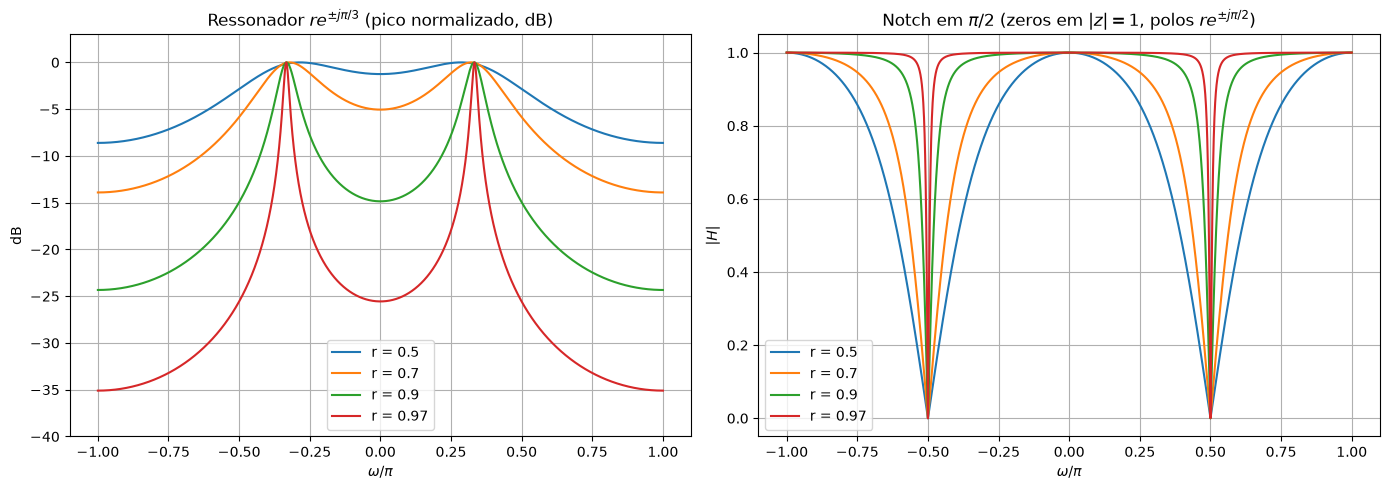

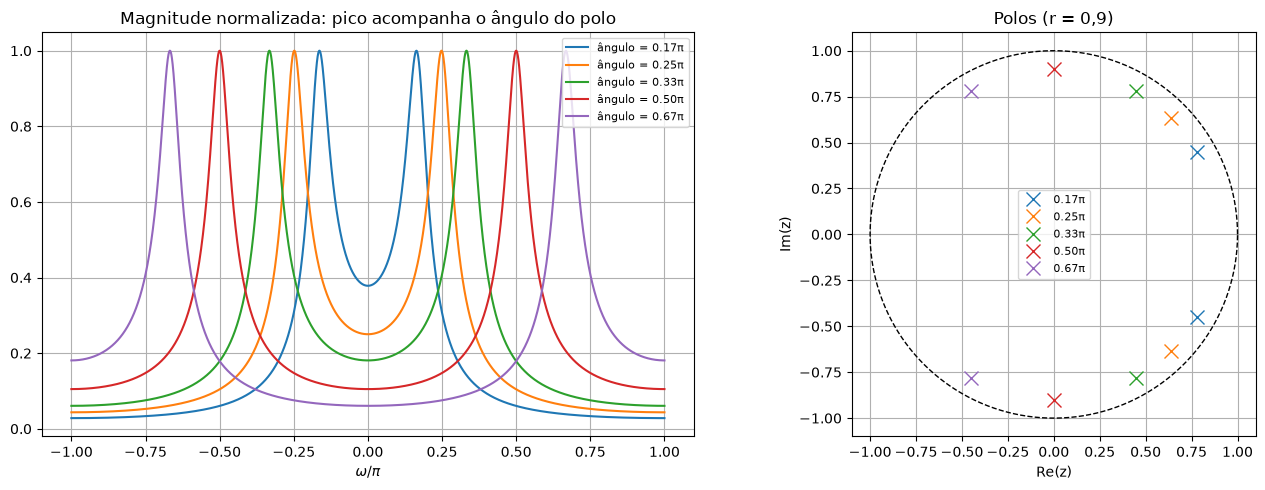


Simulação concluída!


In [1]:
"""
Roteiro de Filtros Digitais - Tópico 7: Polos, Zeros e Resposta em Frequência

    H(z) = K * prod_k (z - z_k) / prod_k (z - p_k),   z = e^{jw}

Para cada configuração de polos e zeros a simulação:
    1. representa o plano-z;            4. representa a magnitude;
    2. representa o círculo unitário;   5. representa a fase;
    3. calcula a resposta em frequência;
    6. relaciona geometricamente polos/zeros com a resposta:
         |H(e^{jw})|  = |K| prod|e^{jw} - z_k| / prod|e^{jw} - p_k|
         ∠H(e^{jw})   = ∠K + sum ∠(e^{jw} - z_k) - sum ∠(e^{jw} - p_k)
       (comprimentos e ângulos dos vetores que ligam cada polo/zero ao ponto
       e^{jw} sobre o círculo unitário).

O ganho K é escolhido para que o máximo de |H| seja 1 (0 dB), salvo quando
indicado. A resposta calculada por vetores é validada contra
scipy.signal.freqz_zpk.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

w = np.linspace(-np.pi, np.pi, 4001)          # rad/amostra
ej = np.exp(1j * w)
th = np.linspace(0, 2 * np.pi, 500)
PI = np.pi


# ============================================================
# FUNÇÕES DE ANÁLISE
# ============================================================

def resposta_vetores(zeros, polos, K, w):
    """H(e^{jw}) pelos vetores ao círculo unitário (interpretação geométrica)."""
    z = np.exp(1j * w)
    dz = [np.abs(z - zk) for zk in zeros]
    dp = [np.abs(z - pk) for pk in polos]
    az = [np.angle(z - zk) for zk in zeros]
    ap = [np.angle(z - pk) for pk in polos]
    mod = abs(K) * (np.prod(dz, axis=0) if dz else 1.0) / \
        (np.prod(dp, axis=0) if dp else 1.0)
    fase = np.angle(K) + (np.sum(az, axis=0) if az else 0.0) \
        - (np.sum(ap, axis=0) if ap else 0.0)
    return mod * np.exp(1j * fase)


def ganho_pico_unitario(zeros, polos, w):
    """K tal que max|H| = 1."""
    H1 = resposta_vetores(zeros, polos, 1.0, w)
    return 1.0 / np.max(np.abs(H1))


def largura_3db(mag, w, i_pico):
    """Largura (rad) em que |H| >= pico/√2, ao redor do pico."""
    alvo = mag[i_pico] / np.sqrt(2)
    i = i_pico
    while i > 0 and mag[i] >= alvo:
        i -= 1
    j = i_pico
    while j < len(mag) - 1 and mag[j] >= alvo:
        j += 1
    return w[j] - w[i]


def par(r, ang):
    """Par complexo conjugado r e^{±j ang}."""
    return [r * np.exp(1j * ang), r * np.exp(-1j * ang)]


# ============================================================
# CONFIGURAÇÕES
# ============================================================
# Cada configuração: zeros, polos, ganho (None = normaliza pico em 1) e
# descrição curta do efeito esperado.

C = {}


def nova(nome, zeros, polos, desc, K=None):
    zeros, polos = list(zeros), list(polos)
    if K is None:
        K = ganho_pico_unitario(zeros, polos, w)
    C[nome] = dict(zeros=zeros, polos=polos, K=K, desc=desc)


nova("A. Polo real positivo (0,8)", [], [0.8], "passa-baixas")
nova("B. Polo real negativo (-0,8)", [], [-0.8], "passa-altas")
nova("C. Zero em z = 1, polo em 0,9", [1.0], [0.9], "bloqueia DC (passa-altas)")
nova("D. Zero em z = -1, polo em 0,5", [-1.0], [0.5], "anula ω = π (passa-baixas)")
nova("E. Polos 0,9e^{±jπ/3}", [], par(0.9, PI / 3), "ressonador em ω ≈ π/3")
nova("F. Zeros e^{±jπ/2}, polos 0,9e^{±jπ/2}", par(1.0, PI / 2),
     par(0.9, PI / 2), "rejeita-faixa (notch) em π/2")
nova("G. Zeros em ±1, polos 0,9e^{±jπ/2}",
     [1.0, -1.0], par(0.9, PI / 2), "passa-faixa centrado em π/2")
nova("H. Passa-tudo: zero 1/0,8, polo 0,8", [1 / 0.8], [0.8],
     "|H| constante, só a fase muda")
nova("I. Polo fora do círculo (1,25)", [], [1.25],
     "|H| existe, mas causal seria instável")

# ============================================================
# 1-5. CÁLCULO E VALIDAÇÃO
# ============================================================

print("CONFIGURAÇÕES DE POLOS E ZEROS")
print("=" * 112)
print(f"{'Configuração':<42}{'K':>9}{'max|H|':>9}{'min|H| (dB)':>13}"
      f"{'ω do máx/π':>12}{'erro vetores x freqz_zpk':>26}")
print("-" * 112)
for nome, c in C.items():
    c["H"] = resposta_vetores(c["zeros"], c["polos"], c["K"], w)
    _, H_sp = signal.freqz_zpk(c["zeros"], c["polos"], c["K"], worN=w)
    c["erro"] = np.max(np.abs(c["H"] - H_sp))
    c["mag"] = np.abs(c["H"])
    c["db"] = 20 * np.log10(np.maximum(c["mag"], 1e-12))
    c["fase"] = np.where(c["mag"] > 1e-9, np.angle(c["H"]), np.nan)
    pos = w >= 0                       # espectro simétrico: só ω >= 0
    i_max = np.argmax(np.where(pos, c["mag"], -1))
    c["w_max"] = w[i_max]
    c["constante"] = np.ptp(c["mag"]) < 1e-9
    mn = c["mag"].min()
    mn_txt = "-inf (nulo)" if mn < 1e-9 else f"{20 * np.log10(mn):.2f}"
    w_txt = "constante" if c["constante"] else f"{c['w_max'] / PI:.3f}"
    print(f"{nome:<42}{c['K']:>9.4f}{c['mag'].max():>9.4f}{mn_txt:>13}"
          f"{w_txt:>12}{c['erro']:>26.2e}")

# ============================================================
# 6. RELAÇÃO GEOMÉTRICA: VETORES EM FREQUÊNCIAS ESCOLHIDAS
# ============================================================

print("\nINTERPRETAÇÃO GEOMÉTRICA (distâncias do ponto e^{jw} a cada polo/zero)")
print("=" * 98)
for nome in ["E. Polos 0,9e^{±jπ/3}", "F. Zeros e^{±jπ/2}, polos 0,9e^{±jπ/2}"]:
    c = C[nome]
    print(nome)
    print(f"  {'ω/π':>6}{'∏|e^{jω}-z_k|':>16}{'∏|e^{jω}-p_k|':>16}"
          f"{'K·∏z/∏p':>12}{'|H| (freqz_zpk)':>18}")
    for wk in [0.0, PI / 6, PI / 3, PI / 2, 2 * PI / 3, PI]:
        z = np.exp(1j * wk)
        pz = np.prod([abs(z - zk) for zk in c["zeros"]]) if c["zeros"] else 1.0
        pp = np.prod([abs(z - pk) for pk in c["polos"]])
        _, Hs = signal.freqz_zpk(c["zeros"], c["polos"], c["K"], worN=[wk])
        print(f"  {wk / PI:>6.3f}{pz:>16.4f}{pp:>16.4f}"
              f"{abs(c['K']) * pz / pp:>12.4f}{abs(Hs[0]):>18.4f}")
    print()

# ============================================================
# EFEITO DO RAIO DOS POLOS (proximidade ao círculo)
# ============================================================

raios = [0.5, 0.7, 0.9, 0.97]
print("RESSONADOR: polos r e^{±jπ/3}")
print("=" * 78)
print(f"{'r':>6}{'ω do pico/π':>14}{'|H| pico/|H(0)|':>18}{'largura -3 dB (rad)':>22}"
      f"{'2(1-r)':>10}")
print("-" * 78)
res_r = {}
for r in raios:
    zs, ps = [], par(r, PI / 3)
    Hr = np.abs(resposta_vetores(zs, ps, 1.0, w))
    Hr_n = Hr / Hr.max()
    i = np.argmax(Hr)
    # só ω >= 0 para a largura
    idx_pos = np.where(w >= 0)[0]
    i_pos = idx_pos[np.argmax(Hr[idx_pos])]
    lw = largura_3db(Hr[idx_pos], w[idx_pos], i_pos - idx_pos[0])
    res_r[r] = Hr_n
    h0 = Hr[np.argmin(np.abs(w))]
    print(f"{r:>6}{w[i_pos] / PI:>14.4f}{Hr.max() / h0:>18.2f}{lw:>22.4f}"
          f"{2 * (1 - r):>10.3f}")
print("  (a largura de banda -3 dB é ≈ 2(1-r) quando r é próximo de 1)")

print("\nNOTCH em π/2: zeros em e^{±jπ/2}, polos r e^{±jπ/2}")
print("=" * 78)
print(f"{'r':>6}{'largura -3 dB (rad)':>22}{'|H(0)|':>10}{'|H(π/2±0,05)|':>18}")
res_n = {}
for r in raios:
    zs, ps = par(1.0, PI / 2), par(r, PI / 2)
    Hn = np.abs(resposta_vetores(zs, ps, 1.0, w))
    K_n = 1.0 / Hn[np.argmin(np.abs(w))]          # ganho DC = 1
    Hn = K_n * Hn
    res_n[r] = Hn
    # largura da região onde |H| < 1/√2
    abaixo = np.where((Hn < 1 / np.sqrt(2)) & (w > 0))[0]
    larg = w[abaixo[-1]] - w[abaixo[0]] if len(abaixo) else np.nan
    i05 = np.argmin(np.abs(w - (PI / 2 + 0.05)))
    print(f"{r:>6}{larg:>22.4f}{Hn[np.argmin(np.abs(w))]:>10.3f}{Hn[i05]:>18.3f}")

# ============================================================
# MOVIMENTO DE UM POLO: ÂNGULO -> FREQUÊNCIA DO PICO
# ============================================================

angulos = [PI / 6, PI / 4, PI / 3, PI / 2, 2 * PI / 3]
print("\nÂNGULO DO POLO x FREQUÊNCIA DO PICO (r = 0,9)")
print("=" * 60)
print(f"{'ângulo do polo/π':>18}{'ω do pico/π':>14}{'diferença/π':>14}")
res_a = {}
for ang in angulos:
    Ha = np.abs(resposta_vetores([], par(0.9, ang), 1.0, w))
    res_a[ang] = Ha / Ha.max()
    ip = np.argmax(np.where(w >= 0, Ha, -1))
    print(f"{ang / PI:>18.3f}{w[ip] / PI:>14.4f}{(w[ip] - ang) / PI:>14.4f}")
print("  (o pico fica próximo do ângulo do polo; a diferença vem do polo "
      "conjugado)")

# ============================================================
# FIGURAS
# ============================================================


def plano_z(ax, c, titulo=None):
    ax.plot(np.cos(th), np.sin(th), "k--", linewidth=1, label="|z| = 1")
    zs = np.array(c["zeros"], dtype=complex)
    ps = np.array(c["polos"], dtype=complex)
    if len(zs):
        ax.plot(zs.real, zs.imag, "o", markerfacecolor="none", markersize=10,
                color="C0", label="Zeros")
    if len(ps):
        ax.plot(ps.real, ps.imag, "x", markersize=10, color="C3",
                label="Polos")
    lim = max(1.3, 1.1 * max([abs(v) for v in list(zs) + list(ps)] + [1]))
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.axhline(0, color="k", linewidth=0.4)
    ax.axvline(0, color="k", linewidth=0.4)
    ax.set_xlabel("Re(z)")
    ax.set_ylabel("Im(z)")
    ax.grid(True)
    if titulo:
        ax.set_title(titulo, fontsize=9)


def painel(nomes, titulo):
    fig, eixos = plt.subplots(len(nomes), 3, figsize=(15, 3.9 * len(nomes)),
                              squeeze=False)
    for lin, nome in zip(eixos, nomes):
        c = C[nome]
        plano_z(lin[0], c, f"{nome}\n({c['desc']})")
        lin[0].legend(fontsize=7, loc="lower left")
        lin[1].plot(w / PI, c["mag"], linewidth=2)
        lin[1].set_ylabel(r"$|H(e^{j\omega})|$")
        lin[1].set_title("Magnitude")
        lin[2].plot(w / PI, c["fase"], linewidth=2, color="C1")
        lin[2].set_ylabel("Fase (rad)")
        lin[2].set_title("Fase")
        for ax in lin[1:]:
            ax.set_xlabel(r"$\omega/\pi$")
            ax.grid(True)
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()


painel(list(C)[0:4], "Polos e zeros reais: magnitude e fase")
painel(list(C)[4:7], "Pares complexos conjugados: ressonador, notch e passa-faixa")
painel(list(C)[7:9], "Passa-tudo e polo fora do círculo unitário")

# Fig: magnitude em dB das configurações juntas
fig, ax = plt.subplots(figsize=(11, 5.5))
for nome, c in C.items():
    ax.plot(w / PI, c["db"], label=nome)
ax.set_ylim(-60, 15)
ax.set_xlabel(r"$\omega/\pi$")
ax.set_ylabel("dB")
ax.set_title("Magnitude (dB) de todas as configurações")
ax.legend(fontsize=7, ncol=2)
ax.grid(True)
plt.tight_layout()
plt.show()

# Fig: interpretação geométrica - vetores em vários ω
def vetores(c, freqs, titulo, ncols=3):
    fig = plt.figure(figsize=(5.3 * ncols, 5 * 2))
    gs = fig.add_gridspec(2, ncols)
    for i, wk in enumerate(freqs):
        ax = fig.add_subplot(gs[0, i])
        plano_z(ax, c)
        zp = np.exp(1j * wk)
        ax.plot(zp.real, zp.imag, "ko", markersize=7)
        for zk in c["zeros"]:
            ax.annotate("", xy=(zp.real, zp.imag), xytext=(zk.real if isinstance(zk, complex) else zk, zk.imag if isinstance(zk, complex) else 0),
                        arrowprops=dict(arrowstyle="->", color="C0"))
        for pk in c["polos"]:
            ax.annotate("", xy=(zp.real, zp.imag), xytext=(pk.real, pk.imag),
                        arrowprops=dict(arrowstyle="->", color="C3"))
        dz = np.prod([abs(zp - zk) for zk in c["zeros"]]) if c["zeros"] else 1
        dp = np.prod([abs(zp - pk) for pk in c["polos"]])
        ax.set_title(rf"$\omega$ = {wk / PI:.2f}π: $\prod d_z$ = {dz:.3f}, "
                     rf"$\prod d_p$ = {dp:.3f}" "\n"
                     rf"$|H|$ = {abs(c['K']) * dz / dp:.3f}", fontsize=9)
    ax = fig.add_subplot(gs[1, :])
    ax.plot(w / PI, c["mag"], linewidth=2)
    for wk in freqs:
        iw = np.argmin(np.abs(w - wk))
        ax.plot(w[iw] / PI, c["mag"][iw], "ko")
    ax.set_xlabel(r"$\omega/\pi$")
    ax.set_ylabel(r"$|H|$")
    ax.set_title("Magnitude: pontos marcados correspondem aos vetores acima")
    ax.grid(True)
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()


vetores(C["E. Polos 0,9e^{±jπ/3}"], [0.0, PI / 3, 2 * PI / 3],
        "Ressonador: distância ao polo domina o valor de |H|")
vetores(C["F. Zeros e^{±jπ/2}, polos 0,9e^{±jπ/2}"], [0.0, PI / 2 - 0.2, PI / 2],
        "Notch: o zero sobre o círculo anula |H| em ω = π/2")

# Fig: efeito do raio
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for r in raios:
    eixos[0].plot(w / PI, 20 * np.log10(res_r[r]), label=f"r = {r}")
    eixos[1].plot(w / PI, res_n[r], label=f"r = {r}")
eixos[0].set_ylim(-40, 3)
eixos[0].set_title(r"Ressonador $re^{\pm j\pi/3}$ (pico normalizado, dB)")
eixos[1].set_title(r"Notch em $\pi/2$ (zeros em $|z|=1$, polos $re^{\pm j\pi/2}$)")
eixos[0].set_ylabel("dB")
eixos[1].set_ylabel(r"$|H|$")
for ax in eixos:
    ax.set_xlabel(r"$\omega/\pi$")
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

# Fig: efeito do ângulo
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for ang in angulos:
    eixos[0].plot(w / PI, res_a[ang], label=rf"ângulo = {ang / PI:.2f}π")
    eixos[1].plot(*[np.cos(ang) * 0.9, np.sin(ang) * 0.9], "x", markersize=10,
                  label=rf"{ang / PI:.2f}π")
    eixos[1].plot(np.cos(ang) * 0.9, -np.sin(ang) * 0.9, "x", markersize=10,
                  color=eixos[1].lines[-1].get_color())
eixos[1].plot(np.cos(th), np.sin(th), "k--", linewidth=1)
eixos[1].set_aspect("equal")
eixos[1].set_title("Polos (r = 0,9)")
eixos[1].set_xlabel("Re(z)")
eixos[1].set_ylabel("Im(z)")
eixos[0].set_title("Magnitude normalizada: pico acompanha o ângulo do polo")
eixos[0].set_xlabel(r"$\omega/\pi$")
for ax in eixos:
    ax.grid(True)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("\nSimulação concluída!")